# Numerics for *Finite de Finetti for convex bodies and polynomial optimization*

This notebook reproduces the numbers, the table and the figure of the section
*Numerical illustration: non-local games over polygon theories* of

> J. A. Zeiss, G. Ko&szlig;mann, R. Schwonnek, M. Pl&aacute;vala,
> *Finite de Finetti for convex bodies and polynomial optimization*, arXiv:2601.15184.

**What is computed.** The assemblage value $\gamma^*(G)$ of the CHSH game —
the paper's polynomial-optimization formulation of the game value — for four
experiments with polytopic local state spaces $K_B$: the classical bit, the
square gbit ("boxworld"), the strongly self-dual regular pentagon, and the
pentagon with the local *inequality* constraint $q_{1|0}\geq 0.7$. Three
things are computed and compared:

1. the **outer hierarchy** $\Sigma^n$ (theorem *Convergence of the hierarchy*):
   levels $p^{(n)}\downarrow\gamma^*$, each an **exact linear program**;
2. the **rounding scheme** (theorem *Convergent inner sequence*): feasible
   product strategies with values $L^{(n)}\leq\gamma^*$ obtained from the
   level-$n$ optimizer, so that outer and inner values *sandwich* the optimum;
3. the **exact optimum** $\gamma^*$ itself, computed directly and certified in
   exact arithmetic (`exact_game_value.py`), as the reference.

**How to run.** All cells execute top-to-bottom. Levels $n\leq 3$ are recomputed
live (seconds); levels $n=4,5$ (minutes of solver time) are loaded from the
shipped `results.json`, the run behind Table 1 of the paper. Set
`RUN_FULL = True` to recompute everything (15–40 min on one core, ~3 GB RAM).

**Reproducibility.** The outer values $p^{(n)}$ are LP optima and reproduce to
$\sim10^{-12}$ on any machine. The rounded values $L^{(n)}$ depend on *which*
optimizer of the (degenerate) optimal face the LP solver returns — observation
(e) of the paper — and can therefore differ from the shipped digits on another
HiGHS build or platform; every such value is still a valid lower bound attained
by an explicit feasible strategy. The checks below treat $p^{(n)}$ strictly and
$L^{(n)}$ by validity ($L^{(n)}\leq\gamma^*$, feasibility), not by digits.

**Dependencies.** `numpy`, `scipy`, `highspy` (HiGHS), `matplotlib`, and the
library `gpt_definetti_games.py` next to this notebook.

In [1]:
import json, os, time, itertools
import numpy as np

from gpt_definetti_games import (
    GameProblem, SymSpace, chsh_coefficients, classical_bit, cs_square,
    eps_functional, hierarchy_level_full, hierarchy_level_symfull,
    inner_rounding, pentagon_selfdual, square_gbit)

RUN_FULL = False        # True: recompute levels n = 4, 5 as well (15-40 min)
CACHE = json.load(open("results.json"))   # the run behind Table 1 of the paper
NAMES = ["classical bit", "square gbit", "pentagon", "pentagon+ineq"]
s5 = np.sqrt(5.0)
# exact optima gamma*(CHSH), closed forms certified by exact_game_value.py
EXACT = {"classical bit": 3/4, "square gbit": 1.0,
         "pentagon": (2*s5 - 1)/4, "pentagon+ineq": 3*(9 + s5)/40}
TOL = 1e-8              # LP solver tolerance scale

# soft-assertion bookkeeping: the notebook keeps running and reports a
# summary at the end
CHECKS = []
def check(name, cond):
    CHECKS.append((name, bool(cond)))
    print(("PASS  " if cond else "FAIL  ") + name)

import scipy, matplotlib, highspy
print("numpy", np.__version__, "| scipy", scipy.__version__,
      "| highspy", highspy.Highs().version(), "| matplotlib", matplotlib.__version__)

numpy 2.4.4 | scipy 1.17.1 | highspy 1.15.1 | matplotlib 3.10.9


## 1&nbsp;&nbsp;Local state spaces (polytopic theories)

A state space is stored as the base $K=\{x : u(x)=1\}$ of a polyhedral cone
$C\subset\mathbb R^d$, described by its extreme rays (`gens`, the vertices of
$K$), the extreme rays of the dual cone (`dual`, the facets of $C$ / extremal
effects, normalized so that $\max_j h(g_j)=1$), the order unit $u$ and a
reference interior state $\tau$.

The **pentagon** uses the circumradius $r_5=\sqrt{\sec(\pi/5)}$ of Janotta,
Gogolin, Barrett and Brunner, for which the pentagon is *strongly* self-dual:
the dual rays, normalized by their first coordinate, **coincide with the
vertices** (odd polygons; for even polygons the dual is a copy of the polygon
rotated by $\pi/m$, as the **square gbit** with vertices $(1,\pm1,\pm1)$ shows —
weak self-duality). The **classical bit** is the $1$-simplex.

PASS  pentagon is strongly self-dual: dual ray set = vertex set
PASS  square gbit is only weakly self-dual: dual rays = square rotated by pi/4 (and rescaled)


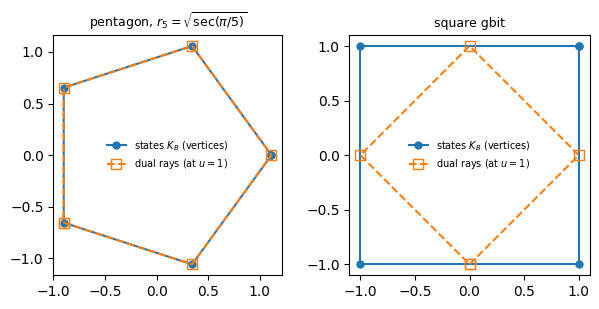

In [2]:
pent, sq, cb = pentagon_selfdual(), square_gbit(), classical_bit()

def dual_polygon(K):
    return np.array([h / h[0] for h in K.dual])     # dual rays at u = 1

def same_point_set(A, B, tol=1e-9):
    return all(min(np.abs(B - a).max(axis=1)) < tol for a in A) and len(A) == len(B)

check("pentagon is strongly self-dual: dual ray set = vertex set",
      same_point_set(dual_polygon(pent), pent.gens))
check("square gbit is only weakly self-dual: dual rays = square rotated by pi/4 (and rescaled)",
      not same_point_set(dual_polygon(sq), sq.gens)
      and same_point_set(dual_polygon(sq),
                         np.array([[1, np.cos(a), np.sin(a)] for a in np.pi/2*np.arange(4)])))

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(6.2, 3.1))
for ax, K, title in zip(axes, (pent, sq), ("pentagon, $r_5=\\sqrt{\\sec(\\pi/5)}$", "square gbit")):
    P = np.vstack([K.gens[:, 1:], K.gens[:1, 1:]])
    D = dual_polygon(K); D = np.vstack([D[:, 1:], D[:1, 1:]])
    ax.plot(P[:, 0], P[:, 1], "-o", ms=5, label="states $K_B$ (vertices)")
    ax.plot(D[:, 0], D[:, 1], "--s", ms=7, mfc="none", label="dual rays (at $u=1$)")
    ax.set_aspect("equal"); ax.set_title(title, fontsize=9); ax.legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 2&nbsp;&nbsp;The game as polynomial optimization with local constraints

For the CHSH game ($|\mathcal A|=|\mathcal B|=|\mathcal X|=|\mathcal Y|=2$,
$g_{abxy}=\tfrac14\,[a\oplus b = x\wedge y]$) the paper's assemblage formulation
maximizes a **bilinear** objective over two convex bodies,

$$K_{\mathrm{asm}}=CS^1_{2,2}\,\hat\otimes\,K_B \quad\text{(Alice's assemblages)},\qquad
K_{\mathrm{mm}}=\{N\in A(K_B)^+\hat\otimes CS^+_{2,2} : (\mathrm{id}\otimes 1_{CS})(N)=1_{K_B}\}\quad\text{(Bob's multimeters)},$$

with the multimeter normalization playing the role of the local equality
constraint $F_B$ of the hierarchy, imposed on **every copy** of the extension in
$\Sigma^n$. `GameProblem` assembles, for a given $K_B$, the extreme rays of
$C_{\mathrm{asm}}^*$ and $C_{\mathrm{mm}}^*$ (products of the factor duals — the
facets of the maximal tensor products), the units $u_{\mathrm{asm}}$ and $t$,
the constraint map $F_B$, the bilinear objective $W$, the slot subspace
$\ker F_B$ in which all copies of the extension live, and optionally rows $G_A$
for local **inequality** constraints (constraint (2c)); we use
$q_{1|0}(\xi)\geq 0.7$: Alice answers $1$ on question $0$ at least 70% of the
time.

In [3]:
probs = {}
probs["classical bit"] = GameProblem(cb,   chsh_coefficients(), name="classical bit")
probs["square gbit"]   = GameProblem(sq,   chsh_coefficients(), name="square gbit")
probs["pentagon"]      = GameProblem(pent, chsh_coefficients(), name="pentagon")
GA = np.kron(eps_functional(0, 1), pent.u) - 0.7 * probs["pentagon"].uA
probs["pentagon+ineq"] = GameProblem(pent, chsh_coefficients(), name="pentagon+ineq",
                                     GA_rows=GA[None, :], GA_desc="q_{1|x=0} >= 0.7")
for k, p in probs.items():
    print(f"{k:14s}: dim K_B={p.dP}, |ext C_asm^*|={len(p.DR_A)}, "
          f"|ext C_mm^*|={len(p.DR_B)}, slot dimension after ker F_B={p.dBr}")
# the extreme rays of C_mm^* form a symmetric IC measurement after rescaling
for k, p in probs.items():
    s = float(p.DR_B_red.sum(0) @ p.t_red) / float(p.t_red @ p.t_red)
    check(f"{k}: sum of the dual rays of C_mm^* = {s:.0f} * t  (symmetric IC measurement)",
          np.allclose(p.DR_B_red.sum(0), s * p.t_red, atol=1e-9))

classical bit : dim K_B=2, |ext C_asm^*|=8, |ext C_mm^*|=8, slot dimension after ker F_B=5
square gbit   : dim K_B=3, |ext C_asm^*|=16, |ext C_mm^*|=16, slot dimension after ker F_B=7
pentagon      : dim K_B=3, |ext C_asm^*|=20, |ext C_mm^*|=20, slot dimension after ker F_B=7
pentagon+ineq : dim K_B=3, |ext C_asm^*|=20, |ext C_mm^*|=20, slot dimension after ker F_B=7
PASS  classical bit: sum of the dual rays of C_mm^* = 4 * t  (symmetric IC measurement)
PASS  square gbit: sum of the dual rays of C_mm^* = 8 * t  (symmetric IC measurement)
PASS  pentagon: sum of the dual rays of C_mm^* = 10 * t  (symmetric IC measurement)
PASS  pentagon+ineq: sum of the dual rays of C_mm^* = 10 * t  (symmetric IC measurement)


## 3&nbsp;&nbsp;Exact reference values $\gamma^*(\mathrm{CHSH})$

Both bodies are polytopes and the objective is bilinear, so the optimum is
attained at a pair of vertices; $K_{\mathrm{mm}}\cong E(K_B)\times E(K_B)$ has
at most $12^2=144$ vertices (pairs of extreme effects), and for each of them the
optimization over $K_{\mathrm{asm}}$ is an LP. `exact_game_value.py` solves all
of them and certifies every optimal vertex with an exact dual (Farkas)
certificate over $\mathbb Q(\sqrt5)$. The resulting closed forms are

$$\gamma^* = \tfrac34,\qquad 1,\qquad \tfrac{2\sqrt5-1}{4}\approx 0.8680,\qquad \tfrac{3(9+\sqrt5)}{40}\approx 0.8427$$

for the bit, the gbit, the pentagon and the constrained pentagon. The cell
loads the shipped `exact_game_values.json` (if present) and compares; run
`python3 exact_game_value.py` to recompute it (needs `pycddlib` for the
vertex-enumeration cross-check, `--no-vertices` without it).

In [4]:
if os.path.exists("exact_game_values.json"):
    EX = json.load(open("exact_game_values.json"))["experiments"]
    for k in NAMES:
        check(f"{k}: exact_game_values.json gamma* = {EX[k]['gamma_star']['closed_form']} "
              f"matches the closed form {EXACT[k]:.10f}",
              abs(EX[k]["gamma_star"]["value_float"] - EXACT[k]) < 1e-12)
        print(f"    {EX[k]['gamma_star']['n_certified_lps']} certified LPs, "
              f"optimum attained by {EX[k]['gamma_star']['n_maximising_tuples']} of "
              f"{EX[k]['gamma_star']['n_multimeter_tuples']} multimeter pairs")
else:
    print("exact_game_values.json not found -- using the closed forms")
for k in NAMES:
    check(f"{k}: results.json carries the same exact optimum",
          abs(CACHE[k]["gamma_star_exact"] - EXACT[k]) < 1e-12)

PASS  classical bit: exact_game_values.json gamma* = 3/4 matches the closed form 0.7500000000
    10 certified LPs, optimum attained by 16 of 16 multimeter pairs
PASS  square gbit: exact_game_values.json gamma* = 1 matches the closed form 1.0000000000
    11 certified LPs, optimum attained by 8 of 36 multimeter pairs
PASS  pentagon: exact_game_values.json gamma* = -1/4 + 1/2*sqrt5 matches the closed form 0.8680339887
    24 certified LPs, optimum attained by 40 of 144 multimeter pairs
PASS  pentagon+ineq: exact_game_values.json gamma* = 27/40 + 3/40*sqrt5 matches the closed form 0.8427050983
    24 certified LPs, optimum attained by 30 of 144 multimeter pairs
PASS  classical bit: results.json carries the same exact optimum
PASS  square gbit: results.json carries the same exact optimum
PASS  pentagon: results.json carries the same exact optimum
PASS  pentagon+ineq: results.json carries the same exact optimum


## 4&nbsp;&nbsp;Outer hierarchy $\Sigma^n$: every level an exact LP

For polytopes, membership in the maximal tensor product has an **exact finite
facet description**: $y\in C_{\mathrm{asm}}\hat\otimes C_{\mathrm{mm}}^{\hat\otimes n}$ iff
$(\varphi\otimes\psi_{k_1}\otimes\cdots\otimes\psi_{k_n})(y)\geq0$ for all
extreme dual rays, so every level is a linear program. Three exact reductions
keep the LPs small (they change the parametrization, not the optimum — see
the companion document and `unreduced_checks/`, where the same levels are solved
with none of them):

1. **permutation symmetry** — the extension is stored per multiset of the $n$ copies;
2. **local equalities as a subspace** — every copy lives in $\ker F_B$;
3. **dihedral symmetry** — each facet is replaced by its orbit average under the
   symmetry group of the polygon acting on all tensor factors.

`hierarchy_level_symfull` implements (1)–(3); `hierarchy_level_full` is the
plain full-facet LP (1)–(2) used for the classical bit. Both solve the LP with
the *complete* facet list (HiGHS, tolerances $\sim10^{-8}$).

In [5]:
solvers = {"classical bit": hierarchy_level_full, "square gbit": hierarchy_level_symfull,
           "pentagon": hierarchy_level_symfull, "pentagon+ineq": hierarchy_level_symfull}
outer, Ysol = {k: {} for k in NAMES}, {k: {} for k in NAMES}
quick_levels = [1, 2, 3]
for k in NAMES:
    for n in quick_levels:
        t0 = time.time()
        r, act, Y = solvers[k](probs[k], n, verbose=False, return_solution=True)
        outer[k][n], Ysol[k][n] = r.value, Y
        ref = CACHE[k]["levels"][str(n)]["value"]
        check(f"{k}: p^({n}) = {r.value:.10f} matches results.json ({r.n_vars} vars, "
              f"{r.n_cuts} rows, {time.time()-t0:.1f}s)", abs(r.value - ref) < 1e-6)
for k in NAMES:                       # heavy levels: cache or recompute
    for n in [4, 5]:
        if RUN_FULL:
            r, act, Y = solvers[k](probs[k], n, verbose=False, return_solution=True)
            outer[k][n], Ysol[k][n] = r.value, Y
            check(f"{k}: p^({n}) = {r.value:.10f} matches results.json",
                  abs(r.value - CACHE[k]["levels"][str(n)]["value"]) < 1e-6)
        else:
            outer[k][n] = CACHE[k]["levels"][str(n)]["value"]
print("\nouter levels p^(n), n = 1..5, and the exact optimum:")
for k in NAMES:
    print(f"  {k:14s}", "  ".join(f"{outer[k][n]:.6f}" for n in range(1, 6)),
          f"| gamma* = {EXACT[k]:.6f}")
for k in NAMES:
    vals = [outer[k][n] for n in range(1, 6)]
    check(f"{k}: outer sequence nonincreasing", all(vals[i] >= vals[i+1] - 1e-9 for i in range(4)))
    check(f"{k}: every outer level is an upper bound on gamma*", all(v >= EXACT[k] - TOL for v in vals))

PASS  classical bit: p^(1) = 1.0000000000 matches results.json (30 vars, 64 rows, 0.1s)
PASS  classical bit: p^(2) = 0.7500000000 matches results.json (90 vars, 288 rows, 0.1s)


PASS  classical bit: p^(3) = 0.7500000000 matches results.json (210 vars, 960 rows, 0.2s)
PASS  square gbit: p^(1) = 1.5000000000 matches results.json (15 vars, 32 rows, 0.0s)
PASS  square gbit: p^(2) = 1.0000000000 matches results.json (45 vars, 288 rows, 0.1s)


PASS  square gbit: p^(3) = 1.0000000000 matches results.json (123 vars, 1632 rows, 0.7s)
PASS  pentagon: p^(1) = 1.3416407865 matches results.json (15 vars, 48 rows, 0.0s)
PASS  pentagon: p^(2) = 0.9208203932 matches results.json (45 vars, 456 rows, 0.1s)


PASS  pentagon: p^(3) = 0.9042054869 matches results.json (111 vars, 3184 rows, 1.5s)
PASS  pentagon+ineq: p^(1) = 1.1733126292 matches results.json (15 vars, 52 rows, 0.0s)


PASS  pentagon+ineq: p^(2) = 0.9181365515 matches results.json (45 vars, 486 rows, 0.2s)


PASS  pentagon+ineq: p^(3) = 0.8952138949 matches results.json (111 vars, 3364 rows, 1.6s)

outer levels p^(n), n = 1..5, and the exact optimum:
  classical bit  1.000000  0.750000  0.750000  0.750000  0.750000 | gamma* = 0.750000
  square gbit    1.500000  1.000000  1.000000  1.000000  1.000000 | gamma* = 1.000000
  pentagon       1.341641  0.920820  0.904205  0.894882  0.886817 | gamma* = 0.868034
  pentagon+ineq  1.173313  0.918137  0.895214  0.877414  0.859670 | gamma* = 0.842705
PASS  classical bit: outer sequence nonincreasing
PASS  classical bit: every outer level is an upper bound on gamma*
PASS  square gbit: outer sequence nonincreasing
PASS  square gbit: every outer level is an upper bound on gamma*
PASS  pentagon: outer sequence nonincreasing
PASS  pentagon: every outer level is an upper bound on gamma*
PASS  pentagon+ineq: outer sequence nonincreasing
PASS  pentagon+ineq: every outer level is an upper bound on gamma*


**Closed forms.** The pentagon levels $p^{(1)}=3/\sqrt5$ and
$p^{(2)}=(6\sqrt5+5)/20$ are algebraic numbers recognized from the LP optima;
the outer gap $p^{(n)}-\gamma^*$ of the unconstrained pentagon decays roughly
like $0.1/n$ (observation (c)), faster than the $n^{-1/2}$ rate guaranteed by
the theorem.

In [6]:
check("pentagon: p^(1) = 3/sqrt5", abs(outer["pentagon"][1] - 3/s5) < 1e-9)
check("pentagon: p^(2) = (6 sqrt5 + 5)/20", abs(outer["pentagon"][2] - (6*s5 + 5)/20) < 1e-9)
print("n * (p^(n) - gamma*) for the pentagon:",
      [round((outer["pentagon"][n] - EXACT["pentagon"]) * n, 4) for n in range(1, 6)])
print("n * (p^(n) - gamma*), constrained:   ",
      [round((outer["pentagon+ineq"][n] - EXACT["pentagon+ineq"]) * n, 4) for n in range(1, 6)])
check("pentagon: gap at n=5 is 1.9e-2",
      abs((outer["pentagon"][5] - EXACT["pentagon"]) - 0.019) < 5e-4)
check("pentagon+ineq: gap at n=5 is 1.7e-2",
      abs((outer["pentagon+ineq"][5] - EXACT["pentagon+ineq"]) - 0.017) < 5e-4)

PASS  pentagon: p^(1) = 3/sqrt5
PASS  pentagon: p^(2) = (6 sqrt5 + 5)/20
n * (p^(n) - gamma*) for the pentagon: [np.float64(0.4736), np.float64(0.1056), np.float64(0.1085), np.float64(0.1074), np.float64(0.0939)]
n * (p^(n) - gamma*), constrained:    [np.float64(0.3306), np.float64(0.1509), np.float64(0.1575), np.float64(0.1388), np.float64(0.0848)]
PASS  pentagon: gap at n=5 is 1.9e-2
PASS  pentagon+ineq: gap at n=5 is 1.7e-2


## 5&nbsp;&nbsp;Observation (a): level 1 is the maximal tensor product

At $n=1$ the relaxation optimizes over $K_{\mathrm{asm}}\hat\otimes K_{\mathrm{mm}}$.
Contracting the level-1 optimizer with the Choi tensor $\chi_{A(K_B)^*}$ gives a
normalized, no-signalling table $p(a,b|x,y)$. For the classical bit (simplicial
cone) it is a bona fide no-signalling box — the PR box, $p^{(1)}=1$; for the
square gbit and the pentagon the contraction is not positive on the maximal
tensor product, the table has negative entries and $p^{(1)}$ exceeds $1$
($3/2$ and $3/\sqrt5$).

In [7]:
def pseudo_correlations(prob, Yfull):
    dP = prob.dP
    M = np.zeros((3, 3))           # Choi pairing over the K_B index
    for al in range(3):
        for be in range(3):
            M[al, be] = sum(Yfull[al*dP + i, i*3 + be] for i in range(dP))
    p = np.zeros((2, 2, 2, 2))
    for a, b, x, y in itertools.product(range(2), repeat=4):
        p[a, b, x, y] = eps_functional(x, a) @ M @ eps_functional(y, b)
    return p

g = chsh_coefficients()
PR = np.zeros((2, 2, 2, 2))        # the PR box
for a, b, x, y in itertools.product(range(2), repeat=4):
    PR[a, b, x, y] = 0.5 * float((a ^ b) == (x & y))
for k in NAMES:
    p = probs[k]
    Yfull = Ysol[k][1].reshape(p.dA, p.dBr) @ p.Bred.T
    tab = pseudo_correlations(p, Yfull)
    nsA = max(abs(tab.sum(1)[a, x, 0] - tab.sum(1)[a, x, 1]) for a in range(2) for x in range(2))
    nsB = max(abs(tab.sum(0)[b, 0, y] - tab.sum(0)[b, 1, y]) for b in range(2) for y in range(2))
    print(f"{k:14s}: p^(1) = {outer[k][1]:.6f}, value of the table = {(g*tab).sum():.6f}, "
          f"entries in [{tab.min():+.4f}, {tab.max():+.4f}], no-signalling residual {max(nsA, nsB):.1e}")
    check(f"{k}: level-1 table is normalized and no-signalling",
          np.allclose(tab.sum(axis=(0, 1)), 1.0) and max(nsA, nsB) < 1e-9)
tab_cb = pseudo_correlations(probs["classical bit"],
                             Ysol["classical bit"][1].reshape(6, probs["classical bit"].dBr) @ probs["classical bit"].Bred.T)
check("classical bit: the level-1 table is the PR box, p^(1) = 1", np.allclose(tab_cb, PR) and abs(outer["classical bit"][1] - 1) < 1e-9)
tab_sq = pseudo_correlations(probs["square gbit"],
                             Ysol["square gbit"][1].reshape(9, probs["square gbit"].dBr) @ probs["square gbit"].Bred.T)
check("square gbit: p^(1) = 3/2 with entries down to -1/4",
      abs(outer["square gbit"][1] - 1.5) < 1e-9 and abs(tab_sq.min() + 0.25) < 1e-9)
check("pentagon: p^(1) = 3/sqrt5 > 1", abs(outer["pentagon"][1] - 3/s5) < 1e-9)

classical bit : p^(1) = 1.000000, value of the table = 1.000000, entries in [+0.0000, +0.5000], no-signalling residual 0.0e+00
PASS  classical bit: level-1 table is normalized and no-signalling
square gbit   : p^(1) = 1.500000, value of the table = 1.500000, entries in [-0.2500, +0.7500], no-signalling residual 0.0e+00
PASS  square gbit: level-1 table is normalized and no-signalling
pentagon      : p^(1) = 1.341641, value of the table = 1.341641, entries in [-0.1708, +0.6708], no-signalling residual 1.1e-16
PASS  pentagon: level-1 table is normalized and no-signalling
pentagon+ineq : p^(1) = 1.173313, value of the table = 1.173313, entries in [-0.1935, +0.8935], no-signalling residual 5.6e-17
PASS  pentagon+ineq: level-1 table is normalized and no-signalling
PASS  classical bit: the level-1 table is the PR box, p^(1) = 1
PASS  square gbit: p^(1) = 3/2 with entries down to -1/4
PASS  pentagon: p^(1) = 3/sqrt5 > 1


## 6&nbsp;&nbsp;Inner rounding: feasible strategies from the level-$n$ optimizer

The rounding scheme of the theorem *Convergent inner sequence*, implemented in
`inner_rounding`: from the level-$n$ optimizer $y^{(n)}$, **measure** $m$ of the
$n$ multimeter copies with the symmetric informationally complete measurement
$\{\psi_k/s\}$ ($\sum_k\psi_k=s\,t$), **condition** on the outcome multiset
$z^m$, **marginalize** the remaining copies, and **productize** the conditional
pair $(x_{A|z^m}, x_{B|z^m})$. Feasibility of every candidate is inherited from
the extension: cone membership survives contraction with positive functionals,
$F_B$ holds because every slot lives in $\ker F_B$, and the local inequality
$G_A$ survives by constraint (2c). Reported is
$L^{(n)}=\max_{m}\max_{z^m}\mathrm{Val}(x_{A|z^m},x_{B|z^m})\leq\gamma^*$.

The live values for $n\leq3$ are printed next to the shipped ones; they agree
where the LP solver returns the same optimizer and can differ otherwise
(Section 8). Validity is checked, digits are not.

In [8]:
inner = {k: {} for k in NAMES}
print(f"{'':14s} {'n':>2s} {'L^(n) live':>12s} {'m*':>3s} {'L^(n) shipped':>14s} {'gamma*':>9s}")
for k in NAMES:
    for n in quick_levels:
        rd = inner_rounding(probs[k], n, Ysol[k][n])
        inner[k][n] = rd["best"]
        ref = CACHE[k]["inner"][str(n)]
        flag = "" if abs(rd["best"] - ref["best"]) < 1e-6 else "   (other optimizer -> other value)"
        print(f"{k:14s} {n:2d} {rd['best']:12.8f} {rd['best_m']:3d} {ref['best']:14.8f} {EXACT[k]:9.6f}{flag}")
        check(f"{k}: all rounded candidates at n={n} feasible (min slack {rd['min_slack']:.0e})",
              rd["min_slack"] > -1e-6)
        check(f"{k}: L^({n}) = {rd['best']:.6f} <= gamma* (and <= p^({n}))",
              rd["best"] <= EXACT[k] + TOL and rd["best"] <= outer[k][n] + TOL)
    for n in [4, 5]:
        if RUN_FULL:
            rd = inner_rounding(probs[k], n, Ysol[k][n]); inner[k][n] = rd["best"]
            check(f"{k}: L^({n}) = {rd['best']:.6f} feasible and <= gamma*",
                  rd["min_slack"] > -1e-6 and rd["best"] <= EXACT[k] + TOL)
        else:
            inner[k][n] = CACHE[k]["inner"][str(n)]["best"]
# the per-m mechanism (live, pentagon n=3): conditioning on more copies sharpens the candidates
rd3 = inner_rounding(probs["pentagon"], 3, Ysol["pentagon"][3])
print("\npentagon, n=3 (live optimizer): best value per number m of measured copies")
for m, d in rd3["per_m"].items():
    print(f"   m={m}: best candidate {d['best']:.8f}   mixture value {d['avg']:.8f}")
# shipped run (Table 1): the maximum over m is attained at m = n-1 in every entry
att = all(abs(CACHE[k]["inner"][str(n)]["per_m_best"][str(n-1)] - CACHE[k]["inner"][str(n)]["best"]) < 1e-9
          for k in NAMES for n in range(1, 6))
check("shipped run: the best candidate is attained at m = n-1 for every entry of Table 1", att)
check("shipped run: worst feasibility slack of all rounded candidates >= -1e-10",
      min(CACHE[k]["inner"][str(n)]["min_slack"] for k in NAMES for n in range(1, 6)) > -1e-10)

                n   L^(n) live  m*  L^(n) shipped    gamma*
classical bit   1   0.50000000   0     0.50000000  0.750000
PASS  classical bit: all rounded candidates at n=1 feasible (min slack 0e+00)
PASS  classical bit: L^(1) = 0.500000 <= gamma* (and <= p^(1))
classical bit   2   0.75000000   0     0.75000000  0.750000
PASS  classical bit: all rounded candidates at n=2 feasible (min slack 0e+00)
PASS  classical bit: L^(2) = 0.750000 <= gamma* (and <= p^(2))
classical bit   3   0.75000000   2     0.75000000  0.750000
PASS  classical bit: all rounded candidates at n=3 feasible (min slack -9e-16)
PASS  classical bit: L^(3) = 0.750000 <= gamma* (and <= p^(3))
square gbit     1   0.50000000   0     0.50000000  1.000000
PASS  square gbit: all rounded candidates at n=1 feasible (min slack 2e-01)
PASS  square gbit: L^(1) = 0.500000 <= gamma* (and <= p^(1))
square gbit     2   0.56250000   1     0.56250000  1.000000
PASS  square gbit: all rounded candidates at n=2 feasible (min slack -2e-14)
PA

## 7&nbsp;&nbsp;The sandwich (Table 1 and the figure)

Together the two sequences bracket $\gamma^*(G)$ at every level,
$L^{(n)}\leq\gamma^*(G)\leq p^{(n)}$, with explicit certificates on both sides:
the outer value is an LP optimum, the inner value is attained by an explicit
feasible strategy. For the classical bit the bracket closes at $n=2$ ($3/4$, the
classical CHSH bound), for the square gbit at $n=4$ ($1$, the PR-box value) —
zero-gap certificates of the optimum obtained without external input
(observation (b)). For the pentagon the bracket at $n=5$ is
$[0.7555,\,0.8868]$ around $\gamma^*\approx0.8680$ (observations (c), (d)).

In [9]:
print("Table 1 (shipped run; live values for n<=3 where they differ are shown in Section 6)")
print(f"{'K_B':14s} {'':6s}" + "".join(f"{'n='+str(n):>10s}" for n in range(1, 6)) + f"{'gamma* (exact)':>16s}")
for k in NAMES:
    po = [CACHE[k]["levels"][str(n)]["value"] for n in range(1, 6)]
    li = [CACHE[k]["inner"][str(n)]["best"] for n in range(1, 6)]
    print(f"{k:14s} p^(n) " + "".join(f"{v:10.4f}" for v in po) + f"{EXACT[k]:16.4f}")
    print(f"{'':14s} L^(n) " + "".join(f"{v:10.4f}" for v in li))
    check(f"{k}: exact optimum inside [L^(n), p^(n)] at every level (shipped run)",
          all(li[i] <= EXACT[k] + TOL <= po[i] + 2*TOL for i in range(5)))
    check(f"{k}: shipped inner sequence nondecreasing", all(li[i] <= li[i+1] + 1e-9 for i in range(4)))
cb2 = (CACHE["classical bit"]["levels"]["2"]["value"], CACHE["classical bit"]["inner"]["2"]["best"])
sq4 = (CACHE["square gbit"]["levels"]["4"]["value"], CACHE["square gbit"]["inner"]["4"]["best"])
check("classical bit: zero-gap certificate L^(2) = p^(2) = 3/4", abs(cb2[0] - cb2[1]) < 1e-7 and abs(cb2[0] - 0.75) < 1e-7)
check("square gbit: zero-gap certificate L^(4) = p^(4) = 1", abs(sq4[0] - sq4[1]) < 1e-7 and abs(sq4[0] - 1.0) < 1e-7)
check("square gbit: shipped inner values 9/16 and 5/8 at n = 2, 3",
      abs(CACHE["square gbit"]["inner"]["2"]["best"] - 9/16) < 1e-7 and abs(CACHE["square gbit"]["inner"]["3"]["best"] - 5/8) < 1e-7)
gap5 = EXACT["pentagon"] - CACHE["pentagon"]["inner"]["5"]["best"]
check(f"pentagon: inner gap at n=5 is 0.11 = about six times the outer gap "
      f"(ratio {gap5/(CACHE['pentagon']['levels']['5']['value']-EXACT['pentagon']):.1f})",
      abs(gap5 - 0.1126) < 1e-3)
check("pentagon+ineq: the constraint binds, gamma* drops from 0.868 to 0.843",
      EXACT["pentagon+ineq"] < EXACT["pentagon"] - 0.02)

Table 1 (shipped run; live values for n<=3 where they differ are shown in Section 6)
K_B                         n=1       n=2       n=3       n=4       n=5  gamma* (exact)
classical bit  p^(n)     1.0000    0.7500    0.7500    0.7500    0.7500          0.7500
               L^(n)     0.5000    0.7500    0.7500    0.7500    0.7500
PASS  classical bit: exact optimum inside [L^(n), p^(n)] at every level (shipped run)
PASS  classical bit: shipped inner sequence nondecreasing
square gbit    p^(n)     1.5000    1.0000    1.0000    1.0000    1.0000          1.0000
               L^(n)     0.5000    0.5625    0.6250    1.0000    1.0000
PASS  square gbit: exact optimum inside [L^(n), p^(n)] at every level (shipped run)
PASS  square gbit: shipped inner sequence nondecreasing
pentagon       p^(n)     1.3416    0.9208    0.9042    0.8949    0.8868          0.8680
               L^(n)     0.5000    0.5459    0.6044    0.7074    0.7555
PASS  pentagon: exact optimum inside [L^(n), p^(n)] at every le

figure written: hierarchy_convergence.pdf/.png


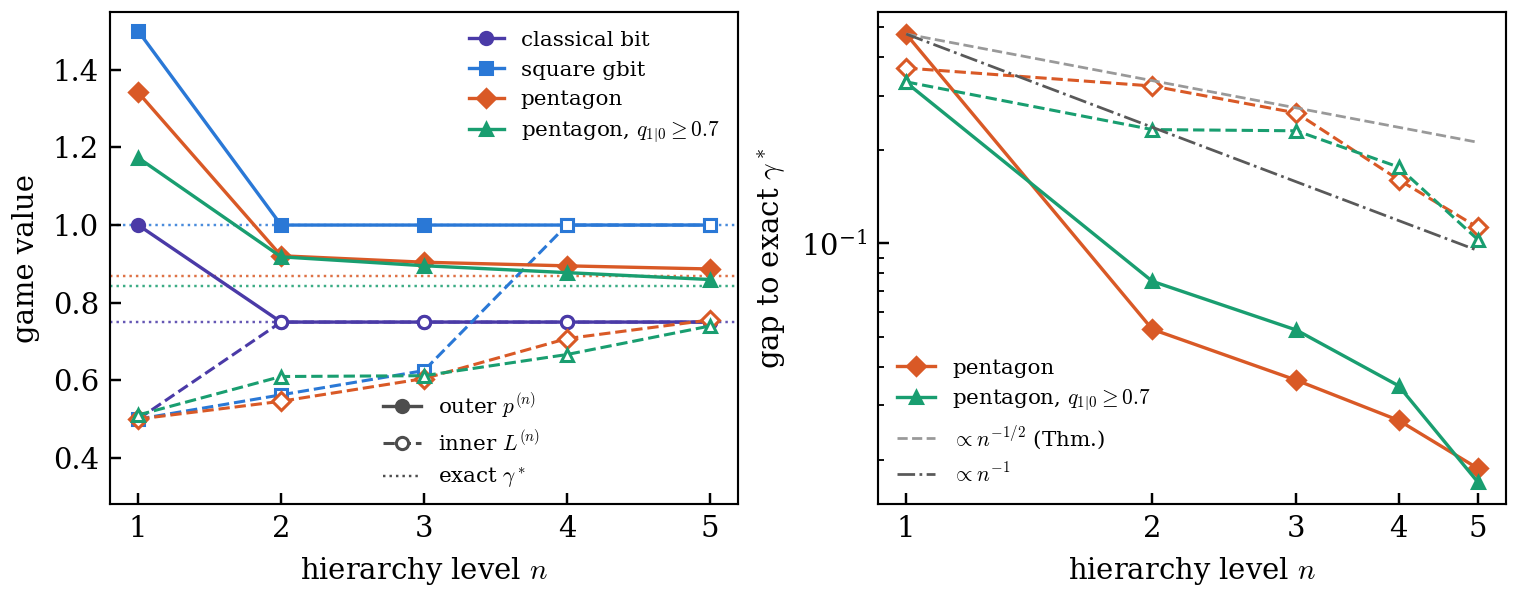

In [10]:
import make_figure   # renders hierarchy_convergence.{pdf,png} from results.json
from IPython.display import Image
Image("hierarchy_convergence.png", width=760)

## 8&nbsp;&nbsp;Observation (e): the inner value depends on the optimizer

The level-$n$ LP typically has many optimizers (its optimal face has positive
dimension); the theorem applies to each of them, but different optimizers round
to different strategies and hence to different lower bounds. Two illustrations:

* **Live:** the square gbit at $n=2$ solved by the two equivalent formulations
  of the library — plain full facet list and orbit-averaged list — gives the
  same $p^{(2)}=1$ but (typically) different $L^{(2)}$: one optimizer rounds to
  a strategy with PR-box correlations already at $n=2$, the other to $9/16$.
* **Shipped data** (`unreduced_checks/direct_inner_sensitivity.json`): the same
  level-2 LPs, written without any reduction and solved by four solver routes
  (dual simplex, interior point with and without crossover, and an equivalent
  "tree" formulation), rounded raw and after group averaging. The ranges quoted
  in the paper are $[0.520, 0.750]$ (bit), $[0.551, 1.000]$ (gbit),
  $[0.532, 0.562]$ (pentagon), $[0.606, 0.615]$ (constrained pentagon). Every
  value is a valid lower bound; the rounding is cheap compared with the LP, so
  one may round several optimizers and keep the best.

In [11]:
# live: two equivalent formulations of the level-2 LP for the square gbit
rA, _, YA = hierarchy_level_full(probs["square gbit"], 2, verbose=False, return_solution=True)
rB, _, YB = hierarchy_level_symfull(probs["square gbit"], 2, verbose=False, return_solution=True)
LA, LB = inner_rounding(probs["square gbit"], 2, YA), inner_rounding(probs["square gbit"], 2, YB)
print(f"square gbit, n=2:  full facet list: p = {rA.value:.10f}, L = {LA['best']:.10f} (m*={LA['best_m']})")
print(f"                   orbit-averaged:  p = {rB.value:.10f}, L = {LB['best']:.10f} (m*={LB['best_m']})")
check("square gbit n=2: both formulations give the same outer value", abs(rA.value - rB.value) < 1e-8)
check("square gbit n=2: both rounded values are valid lower bounds (<= gamma* = 1)",
      max(LA["best"], LB["best"]) <= 1 + TOL)
print("   (the two optimizers differ by", f"{np.abs(YA - YB).max():.3f} in sup norm)")

# shipped data of the unreduced-LP sensitivity study
path = os.path.join("unreduced_checks", "direct_inner_sensitivity.json")
if os.path.exists(path):
    S = json.load(open(path))
    quoted = {"classical bit": (0.520, 0.750), "square gbit": (0.551, 1.000),
              "pentagon": (0.532, 0.562), "pentagon+ineq": (0.606, 0.615)}
    for k in NAMES:
        recs = S[k]["2"]
        vals = [r["L_raw"] for r in recs.values()] + [r["L_avg"] for r in recs.values()]
        print(f"{k:14s} n=2: p^(2) = {max(r['outer_value'] for r in recs.values()):.10f}, "
              f"rounded values over 4 routes x {{raw, averaged}}: [{min(vals):.4f}, {max(vals):.4f}]"
              f"   routes: " + ", ".join(f"{lab}: {r['L_raw']:.4f}" for lab, r in recs.items()))
        check(f"{k}: range of L^(2) over the routes = [{quoted[k][0]:.3f}, {quoted[k][1]:.3f}] as quoted in the paper",
              abs(round(min(vals), 3) - quoted[k][0]) < 1e-9 and abs(round(max(vals), 3) - quoted[k][1]) < 1e-9)
        check(f"{k}: every route value is a valid lower bound (<= gamma*)", max(vals) <= EXACT[k] + TOL)
    r = S["square gbit"]["2"]["explicit-simplex"]
    check("square gbit: one vertex of the optimal face rounds to the PR-box value 1 at m=0",
          abs(r["L_raw"] - 1.0) < 1e-9 and r["m_raw"] == 0)
else:
    print("unreduced_checks/direct_inner_sensitivity.json not found -- skipped")

square gbit, n=2:  full facet list: p = 1.0000000000, L = 1.0000000000 (m*=1)
                   orbit-averaged:  p = 1.0000000000, L = 0.5625000000 (m*=1)
PASS  square gbit n=2: both formulations give the same outer value
PASS  square gbit n=2: both rounded values are valid lower bounds (<= gamma* = 1)
   (the two optimizers differ by 0.500 in sup norm)
classical bit  n=2: p^(2) = 0.7500000000, rounded values over 4 routes x {raw, averaged}: [0.5202, 0.7500]   routes: explicit-simplex: 0.7500, explicit-ipm+xover: 0.7500, explicit-ipm: 0.5494, tree-ipm: 0.5245
PASS  classical bit: range of L^(2) over the routes = [0.520, 0.750] as quoted in the paper
PASS  classical bit: every route value is a valid lower bound (<= gamma*)
square gbit    n=2: p^(2) = 1.0000000000, rounded values over 4 routes x {raw, averaged}: [0.5507, 1.0000]   routes: explicit-simplex: 1.0000, explicit-ipm+xover: 0.6111, explicit-ipm: 0.5666, tree-ipm: 0.5515
PASS  square gbit: range of L^(2) over the routes = [0.55

## 9&nbsp;&nbsp;Summary of checks

* All LPs are solved to HiGHS default tolerances ($\sim10^{-8}$); the reported
  outer digits are the optima of the *complete* (reduced) facet descriptions.
* `reproduce.py` regenerates `results.json` and the figure from scratch;
  `RUN_FULL = True` does the same inside this notebook.
* Runtimes (single core): levels $n\leq3$ seconds; $n=4$ tens of seconds;
  $n=5$ a few minutes per experiment.

In [12]:
fails = [n for n, ok in CHECKS if not ok]
print(f"{len(CHECKS)} checks run, {len(CHECKS)-len(fails)} passed, {len(fails)} failed")
for n in fails:
    print("  FAILED:", n)
assert not fails, "some checks failed"
print("ALL CHECKS PASSED")

95 checks run, 95 passed, 0 failed
ALL CHECKS PASSED
